In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import warnings

warnings.filterwarnings('ignore')

# Set visualization style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

print("Libraries imported successfully!")
print(f"Pandas version: {pd.__version__}")

Libraries imported successfully!
Pandas version: 2.3.3


In [2]:
# Load the restaurant data
df = pd.read_csv('the_hague_restaurants.csv')

print("Dataset loaded successfully!")
print(f"\nShape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\n" + "="*60)
print("First few rows:")
df.head()

Dataset loaded successfully!

Shape: 60 rows, 15 columns

First few rows:


,place_id,name,address,latitude,longitude,rating,user_ratings_total,price_level,types,business_status,full_address,phone,website,open_now,collected_date
0,ChIJXWizKLewxUcRZkf-eWhK5_U,Leonardo Royal Hotel Den Haag Promenade,"Van Stolkweg 1, Den Haag",52.097001,4.287193,4.4,2864,NaN,"gym, lodging, spa, restaurant, food, health, p...",OPERATIONAL,"Van Stolkweg 1, 2585 JL Den Haag, Netherlands",070 352 5161,https://www.leonardo-hotels.com/the-hague/leon...,True,2025-12-08 18:17:52
1,ChIJz01uUDG3xUcRG3sPVyCL_Is,Carlton Ambassador,"Sophialaan 2, Den Haag",52.085669,4.302694,4.4,931,NaN,"lodging, restaurant, food, point_of_interest, ...",OPERATIONAL,"Sophialaan 2, 2514 JP Den Haag, Netherlands",070 363 0363,https://www.carltonambassador.nl/,True,2025-12-08 18:17:52
2,ChIJr0n5mDu3xUcRQA8VOP4EbAE,Hotel Des Indes,"Lange Voorhout 54-56, Den Haag",52.083780,4.313129,4.5,1811,NaN,"lodging, spa, restaurant, food, point_of_inter...",OPERATIONAL,"Lange Voorhout 54-56, 2514 EG Den Haag, Nether...",070 361 2345,https://www.hoteldesindesthehague.com/,True,2025-12-08 18:17:52
3,ChIJIw6-NyK3xUcRN2eDfx9PR18,Mercure Hotel Den Haag Central,"Spui 180, Den Haag",52.076498,4.318043,4.3,1932,NaN,"lodging, restaurant, food, point_of_interest, ...",OPERATIONAL,"Spui 180, 2511 BW Den Haag, Netherlands",070 203 9002,https://all.accor.com/lien_externe.svlt?goto=f...,NaN,2025-12-08 18:17:52
4,ChIJs8vdpxe3xUcRDIeT8asAD0o,Leonardo Hotel Den Haag Babylon,"Bezuidenhoutseweg 53, Den Haag",52.082600,4.324418,4.3,1583,NaN,"lodging, restaurant, food, point_of_interest, ...",OPERATIONAL,"Bezuidenhoutseweg 53, 2595 AA Den Haag, Nether...",070 381 4901,https://www.leonardo-hotels.nl/the-hague/leona...,NaN,2025-12-08 18:17:52


In [3]:
print("DATASET OVERVIEW")
print("="*60)

print("\nColumn names and types:")
print(df.dtypes)

print("\n" + "="*60)
print("\nMissing values:")
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Percentage': missing_pct
})
print(missing_df[missing_df['Missing Count'] > 0].sort_values('Missing Count', ascending=False))

print("\n" + "="*60)
print("\nBasic statistics:")
df.describe()

DATASET OVERVIEW

Column names and types:
place_id               object
name                   object
address                object
latitude              float64
longitude             float64
rating                float64
user_ratings_total      int64
price_level           float64
types                  object
business_status        object
full_address           object
phone                  object
website                object
open_now               object
collected_date         object
dtype: object


Missing values:
             Missing Count  Percentage
price_level             20   33.333333
open_now                 6   10.000000
phone                    1    1.666667


Basic statistics:


,latitude,longitude,rating,user_ratings_total,price_level
count,60.000000,60.000000,60.000000,60.000000,40.000000
mean,52.080540,4.309125,4.275000,1578.216667,2.100000
std,0.012913,0.016027,0.284411,1908.769611,0.378932
min,52.037126,4.255201,3.700000,131.000000,1.000000
25%,52.076717,4.305641,4.100000,525.500000,2.000000
50%,52.079515,4.311128,4.300000,1134.000000,2.000000
75%,52.083932,4.315373,4.500000,1944.250000,2.000000
max,52.114447,4.369563,4.800000,13393.000000,3.000000


In [4]:
print("DATA CLEANING")
print("="*60)

# Create a copy for cleaning
df_clean = df.copy()

# Remove duplicates based on place_id
initial_count = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=['place_id'], keep='first')
duplicates_removed = initial_count - len(df_clean)
print(f"\nDuplicates removed: {duplicates_removed}")

# Remove restaurants with no rating (likely closed or new)
df_clean = df_clean[df_clean['rating'].notna()]
print(f"Restaurants with ratings: {len(df_clean)}")

# Create price level labels
price_mapping = {
    1: '€ (Budget)',
    2: '€€ (Moderate)',
    3: '€€€ (Expensive)',
    4: '€€€€ (Very Expensive)'
}
df_clean['price_category'] = df_clean['price_level'].map(price_mapping)

# Fill missing price levels
df_clean['price_category'] = df_clean['price_category'].fillna('Unknown')

print(f"\nFinal dataset size: {len(df_clean)} restaurants")
print("\n" + "="*60)

DATA CLEANING

Duplicates removed: 0
Restaurants with ratings: 60

Final dataset size: 60 restaurants



RATING ANALYSIS


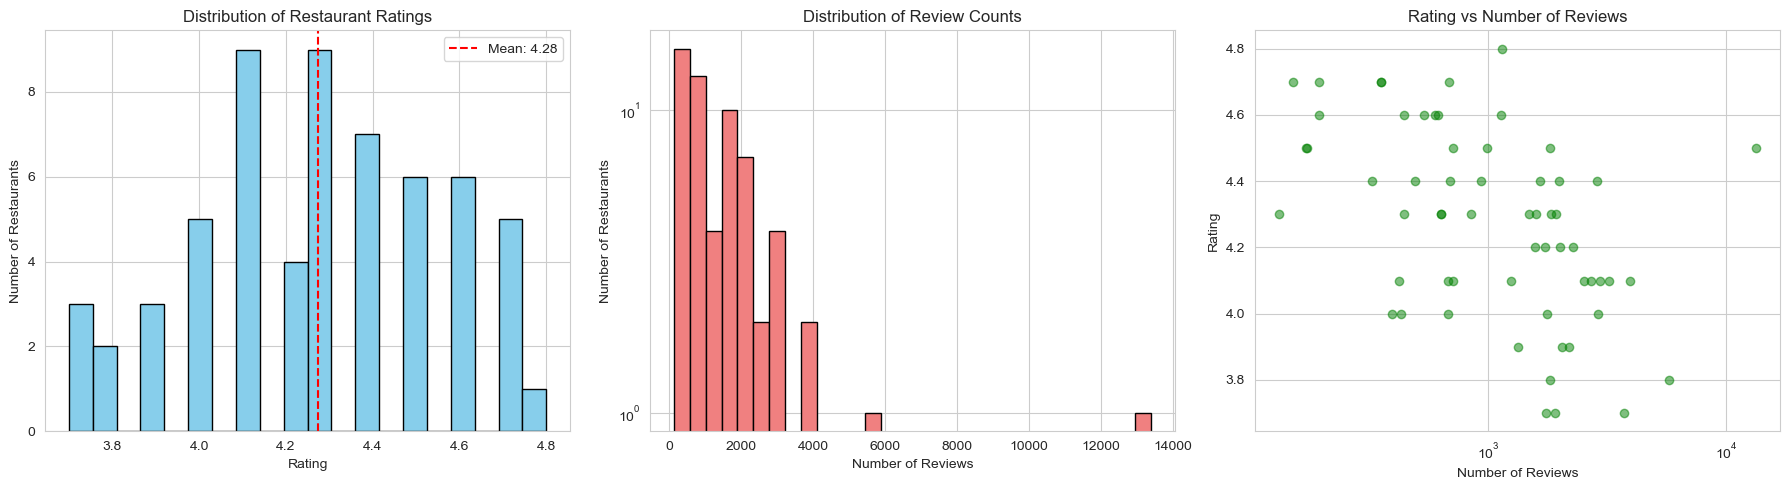


Rating Statistics:
  Mean rating: 4.28
  Median rating: 4.30
  Std deviation: 0.28

Review Statistics:
  Mean reviews: 1578
  Median reviews: 1134
  Max reviews: 13393


In [5]:
print("RATING ANALYSIS")
print("="*60)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Rating distribution
axes[0].hist(df_clean['rating'], bins=20, color='skyblue', edgecolor='black')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Number of Restaurants')
axes[0].set_title('Distribution of Restaurant Ratings')
axes[0].axvline(df_clean['rating'].mean(), color='red', linestyle='--', 
                label=f'Mean: {df_clean["rating"].mean():.2f}')
axes[0].legend()

# Review count distribution (log scale)
axes[1].hist(df_clean['user_ratings_total'], bins=30, color='lightcoral', edgecolor='black')
axes[1].set_xlabel('Number of Reviews')
axes[1].set_ylabel('Number of Restaurants')
axes[1].set_title('Distribution of Review Counts')
axes[1].set_yscale('log')

# Rating vs Review Count scatter
axes[2].scatter(df_clean['user_ratings_total'], df_clean['rating'], 
                alpha=0.5, color='green')
axes[2].set_xlabel('Number of Reviews')
axes[2].set_ylabel('Rating')
axes[2].set_title('Rating vs Number of Reviews')
axes[2].set_xscale('log')

plt.tight_layout()
plt.show()

# Summary statistics
print(f"\nRating Statistics:")
print(f"  Mean rating: {df_clean['rating'].mean():.2f}")
print(f"  Median rating: {df_clean['rating'].median():.2f}")
print(f"  Std deviation: {df_clean['rating'].std():.2f}")
print(f"\nReview Statistics:")
print(f"  Mean reviews: {df_clean['user_ratings_total'].mean():.0f}")
print(f"  Median reviews: {df_clean['user_ratings_total'].median():.0f}")
print(f"  Max reviews: {df_clean['user_ratings_total'].max():.0f}")

PRICE LEVEL ANALYSIS


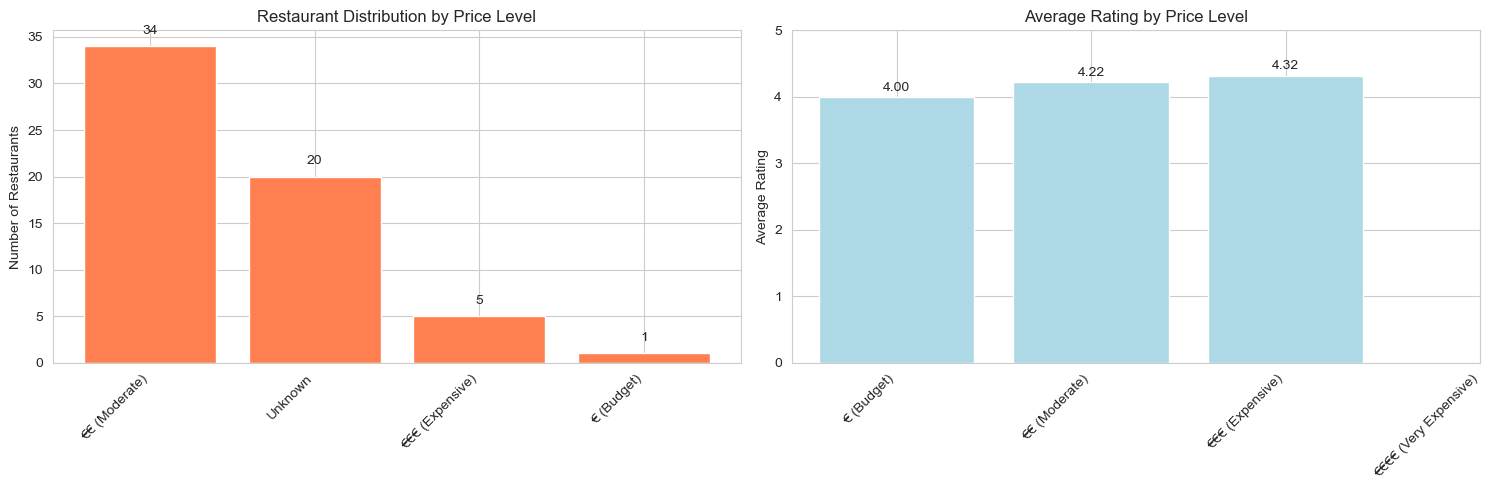


Price level distribution:
price_category
€€ (Moderate)      34
Unknown            20
€€€ (Expensive)     5
€ (Budget)          1
Name: count, dtype: int64

Average rating by price level:
                           mean  count
price_category                        
€ (Budget)             4.000000    1.0
€€ (Moderate)          4.217647   34.0
€€€ (Expensive)        4.320000    5.0
€€€€ (Very Expensive)       NaN    NaN


In [6]:
print("PRICE LEVEL ANALYSIS")
print("="*60)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Price distribution
price_counts = df_clean['price_category'].value_counts()
axes[0].bar(range(len(price_counts)), price_counts.values, color='coral')
axes[0].set_xticks(range(len(price_counts)))
axes[0].set_xticklabels(price_counts.index, rotation=45, ha='right')
axes[0].set_ylabel('Number of Restaurants')
axes[0].set_title('Restaurant Distribution by Price Level')

# Add counts on bars
for i, v in enumerate(price_counts.values):
    axes[0].text(i, v + 1, str(v), ha='center', va='bottom')

# Average rating by price level
price_rating = df_clean[df_clean['price_category'] != 'Unknown'].groupby('price_category')['rating'].agg(['mean', 'count'])
price_rating = price_rating.reindex(['€ (Budget)', '€€ (Moderate)', '€€€ (Expensive)', '€€€€ (Very Expensive)'])

axes[1].bar(range(len(price_rating)), price_rating['mean'].values, color='lightblue')
axes[1].set_xticks(range(len(price_rating)))
axes[1].set_xticklabels(price_rating.index, rotation=45, ha='right')
axes[1].set_ylabel('Average Rating')
axes[1].set_title('Average Rating by Price Level')
axes[1].set_ylim([0, 5])

# Add values on bars
for i, v in enumerate(price_rating['mean'].values):
    axes[1].text(i, v + 0.05, f'{v:.2f}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

print("\nPrice level distribution:")
print(price_counts)
print("\nAverage rating by price level:")
print(price_rating)


CUISINE TYPE ANALYSIS


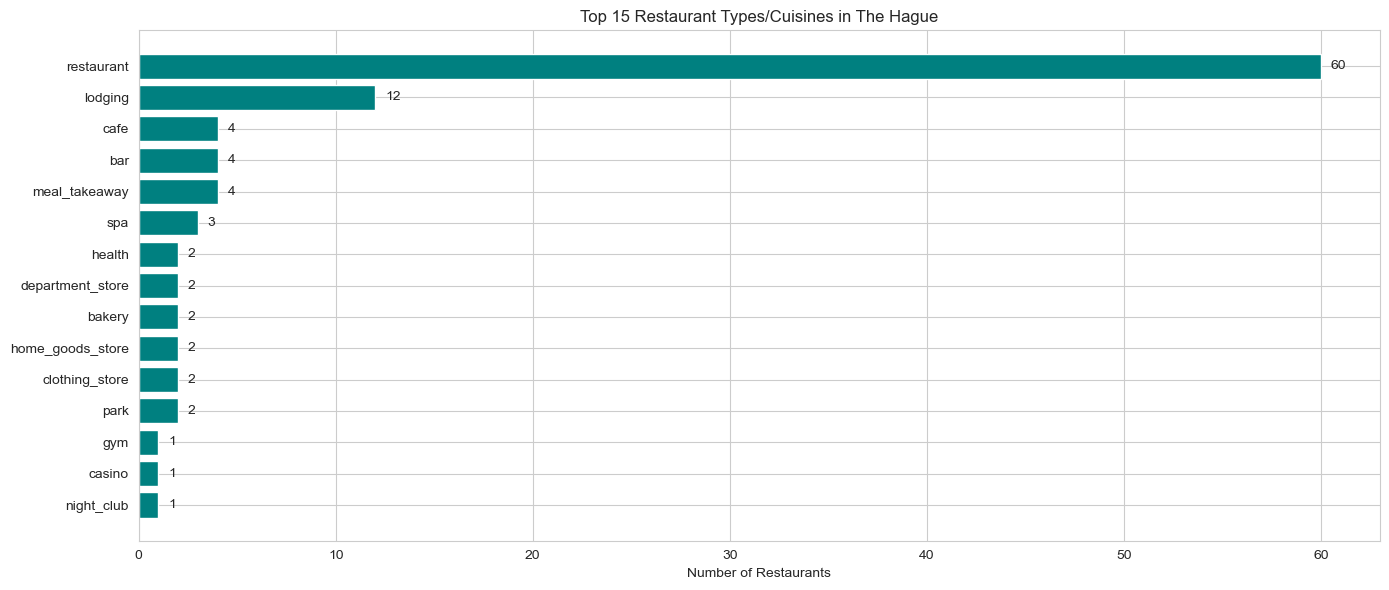


Top 15 restaurant types:
 1. restaurant                    :  60
 2. lodging                       :  12
 3. cafe                          :   4
 4. bar                           :   4
 5. meal_takeaway                 :   4
 6. spa                           :   3
 7. health                        :   2
 8. department_store              :   2
 9. bakery                        :   2
10. home_goods_store              :   2
11. clothing_store                :   2
12. park                          :   2
13. gym                           :   1
14. casino                        :   1
15. night_club                    :   1


In [7]:
print("CUISINE TYPE ANALYSIS")
print("="*60)

# Extract all cuisine types
all_types = []
for types_str in df_clean['types'].dropna():
    types_list = [t.strip() for t in types_str.split(',')]
    all_types.extend(types_list)

# Count cuisine types
type_counts = Counter(all_types)

# Get top 15 cuisine types (excluding generic ones)
exclude_types = ['point_of_interest', 'establishment', 'food', 'store']
filtered_types = {k: v for k, v in type_counts.items() if k not in exclude_types}
top_types = dict(sorted(filtered_types.items(), key=lambda x: x[1], reverse=True)[:15])

# Visualize
plt.figure(figsize=(14, 6))
plt.barh(list(top_types.keys()), list(top_types.values()), color='teal')
plt.xlabel('Number of Restaurants')
plt.title('Top 15 Restaurant Types/Cuisines in The Hague')
plt.gca().invert_yaxis()

# Add counts
for i, (k, v) in enumerate(top_types.items()):
    plt.text(v + 0.5, i, str(v), va='center')

plt.tight_layout()
plt.show()

print("\nTop 15 restaurant types:")
for i, (type_name, count) in enumerate(top_types.items(), 1):
    print(f"{i:2d}. {type_name:30s}: {count:3d}")

GEOGRAPHIC DISTRIBUTION


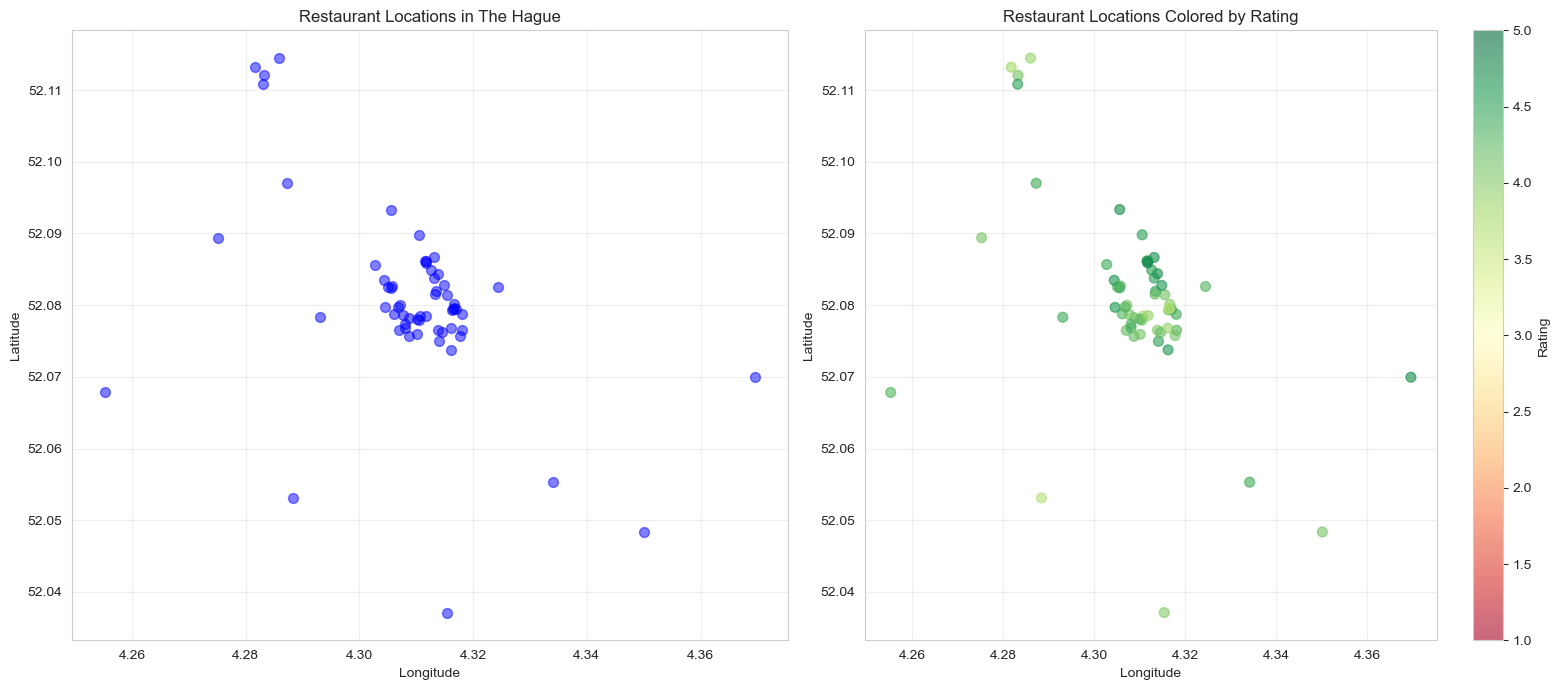


Geographic spread:
  Latitude range: 52.0371 to 52.1144
  Longitude range: 4.2552 to 4.3696


In [8]:
print("GEOGRAPHIC DISTRIBUTION")
print("="*60)

# Create scatter plot of restaurant locations
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Basic location plot
axes[0].scatter(df_clean['longitude'], df_clean['latitude'], 
               alpha=0.5, s=50, color='blue')
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
axes[0].set_title('Restaurant Locations in The Hague')
axes[0].grid(True, alpha=0.3)

# Color by rating
scatter = axes[1].scatter(df_clean['longitude'], df_clean['latitude'], 
                         c=df_clean['rating'], cmap='RdYlGn', 
                         s=50, alpha=0.6, vmin=1, vmax=5)
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')
axes[1].set_title('Restaurant Locations Colored by Rating')
axes[1].grid(True, alpha=0.3)
plt.colorbar(scatter, ax=axes[1], label='Rating')

plt.tight_layout()
plt.show()

print(f"\nGeographic spread:")
print(f"  Latitude range: {df_clean['latitude'].min():.4f} to {df_clean['latitude'].max():.4f}")
print(f"  Longitude range: {df_clean['longitude'].min():.4f} to {df_clean['longitude'].max():.4f}")

In [9]:
print("TOP PERFORMING RESTAURANTS")
print("="*60)

# Top rated restaurants (with minimum reviews threshold)
min_reviews = 50
top_rated = df_clean[df_clean['user_ratings_total'] >= min_reviews].nlargest(10, 'rating')

print(f"\nTop 10 Highest Rated Restaurants (min {min_reviews} reviews):")
print("\n" + "-"*60)
for idx, row in top_rated.iterrows():
    print(f"{row['name']}")
    print(f"  Rating: {row['rating']:.1f} ⭐ ({row['user_ratings_total']:.0f} reviews)")
    print(f"  Price: {row['price_category']}")
    print(f"  Address: {row['address']}")
    print("-"*60)

# Most reviewed restaurants
most_reviewed = df_clean.nlargest(10, 'user_ratings_total')

print(f"\n\nTop 10 Most Reviewed Restaurants:")
print("\n" + "-"*60)
for idx, row in most_reviewed.iterrows():
    print(f"{row['name']}")
    print(f"  Reviews: {row['user_ratings_total']:.0f}")
    print(f"  Rating: {row['rating']:.1f} ⭐")
    print(f"  Price: {row['price_category']}")
    print("-"*60)

TOP PERFORMING RESTAURANTS

Top 10 Highest Rated Restaurants (min 50 reviews):

------------------------------------------------------------
Dekxels
  Rating: 4.8 ⭐ (1140 reviews)
  Price: €€ (Moderate)
  Address: Denneweg 130, Den Haag
------------------------------------------------------------
Relais & Chateaux - Central Park Voorburg
  Rating: 4.7 ⭐ (685 reviews)
  Price: Unknown
  Address: Oosteinde 14, Voorburg
------------------------------------------------------------
Restaurant le Bistrot de la Place
  Rating: 4.7 ⭐ (150 reviews)
  Price: Unknown
  Address: Maliestraat 9, Den Haag
------------------------------------------------------------
Japanese Restaurant Benkei 🇯🇵
  Rating: 4.7 ⭐ (352 reviews)
  Price: €€ (Moderate)
  Address: Denneweg 142, Den Haag
------------------------------------------------------------
Calla's
  Rating: 4.7 ⭐ (353 reviews)
  Price: Unknown
  Address: Laan van Roos en Doorn 51A, Den Haag
------------------------------------------------------------

In [10]:
print("MARKET INSIGHTS & RECOMMENDATIONS")
print("="*60)

# Calculate popularity score (weighted rating)
# Formula: (rating * log(reviews + 1)) to balance quality and popularity
df_clean['popularity_score'] = df_clean['rating'] * np.log1p(df_clean['user_ratings_total'])

print("\n1. MARKET OVERVIEW")
print("-" * 60)
print(f"Total restaurants analyzed: {len(df_clean)}")
print(f"Average rating: {df_clean['rating'].mean():.2f}/5.0")
print(f"Average reviews per restaurant: {df_clean['user_ratings_total'].mean():.0f}")

print("\n2. PRICE POINT OPPORTUNITIES")
print("-" * 60)
price_dist = df_clean['price_category'].value_counts()
for price, count in price_dist.items():
    pct = (count / len(df_clean)) * 100
    print(f"{price:25s}: {count:3d} ({pct:.1f}%)")

print("\n3. RATING BENCHMARKS")
print("-" * 60)
print(f"Top 25% threshold: {df_clean['rating'].quantile(0.75):.2f}+")
print(f"Top 10% threshold: {df_clean['rating'].quantile(0.90):.2f}+")
print(f"Bottom 25%: Below {df_clean['rating'].quantile(0.25):.2f}")

print("\n4. COMPETITION INTENSITY")
print("-" * 60)
high_competition = len(df_clean[df_clean['rating'] >= 4.0])
pct_high_quality = (high_competition / len(df_clean)) * 100
print(f"Restaurants rated 4.0+: {high_competition} ({pct_high_quality:.1f}%)")
print(f"Market saturation level: {'HIGH' if pct_high_quality > 50 else 'MODERATE' if pct_high_quality > 30 else 'LOW'}")

print("\n5. KEY FINDINGS")
print("-" * 60)
print("✓ Most common price point:", price_dist.index[0])
print("✓ Highest rated category:", df_clean.groupby('price_category')['rating'].mean().idxmax())
print("✓ Average successful restaurant:", f"{df_clean['rating'].mean():.1f} stars with {df_clean['user_ratings_total'].median():.0f} reviews")

print("\n" + "="*60)

MARKET INSIGHTS & RECOMMENDATIONS

1. MARKET OVERVIEW
------------------------------------------------------------
Total restaurants analyzed: 60
Average rating: 4.28/5.0
Average reviews per restaurant: 1578

2. PRICE POINT OPPORTUNITIES
------------------------------------------------------------
€€ (Moderate)            :  34 (56.7%)
Unknown                  :  20 (33.3%)
€€€ (Expensive)          :   5 (8.3%)
€ (Budget)               :   1 (1.7%)

3. RATING BENCHMARKS
------------------------------------------------------------
Top 25% threshold: 4.50+
Top 10% threshold: 4.61+
Bottom 25%: Below 4.10

4. COMPETITION INTENSITY
------------------------------------------------------------
Restaurants rated 4.0+: 52 (86.7%)
Market saturation level: HIGH

5. KEY FINDINGS
------------------------------------------------------------
✓ Most common price point: €€ (Moderate)
✓ Highest rated category: Unknown
✓ Average successful restaurant: 4.3 stars with 1134 reviews



In [11]:
print("EXPORTING ANALYSIS RESULTS")
print("="*60)

# Create summary dataset
summary_stats = {
    'Metric': [
        'Total Restaurants',
        'Average Rating',
        'Median Rating',
        'Average Reviews',
        'Median Reviews',
        'Restaurants 4.0+',
        'Restaurants 4.5+'
    ],
    'Value': [
        len(df_clean),
        round(df_clean['rating'].mean(), 2),
        round(df_clean['rating'].median(), 2),
        round(df_clean['user_ratings_total'].mean(), 0),
        round(df_clean['user_ratings_total'].median(), 0),
        len(df_clean[df_clean['rating'] >= 4.0]),
        len(df_clean[df_clean['rating'] >= 4.5])
    ]
}

summary_df = pd.DataFrame(summary_stats)

# Save cleaned data
df_clean.to_csv('the_hague_restaurants_cleaned.csv', index=False)
print("✓ Cleaned data saved: the_hague_restaurants_cleaned.csv")

# Save summary statistics
summary_df.to_csv('analysis_summary.csv', index=False)
print("✓ Summary statistics saved: analysis_summary.csv")

# Save top performers
top_rated.to_csv('top_rated_restaurants.csv', index=False)
print("✓ Top rated restaurants saved: top_rated_restaurants.csv")

print("\n" + "="*60)
print("Analysis complete! Files ready for Power BI import.")

EXPORTING ANALYSIS RESULTS
✓ Cleaned data saved: the_hague_restaurants_cleaned.csv
✓ Summary statistics saved: analysis_summary.csv
✓ Top rated restaurants saved: top_rated_restaurants.csv

Analysis complete! Files ready for Power BI import.
